In [17]:
import json
import os
 
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import umap
import hdbscan
import unicodedata
from sklearn.metrics import silhouette_score
from collections import defaultdict
import glob
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

In [186]:
CARPETA_JUICIOS = "juicios_llm_qwen_model_"
CARPETA_EMBEDDINGS = "embeddings"

UMAP_N_COMPONENTS = 12
HDBSCAN_MIN_SAMPLES = None
MIN_OCURRENCIAS_PARA_CLUSTER = 8   # palabras con menos ocurrencias no se agrupan

MIN_TWEETS_POR_SENTIDO_LLM = 5
 
ETIQUETA_RUIDO_LLM = "ruido_llm"

MCS_FRACCION = 0.05   # min_cluster_size ≈ 5% de las ocurrencias de la palabra
MCS_MINIMO = 5
MCS_MAXIMO = 50

In [193]:
def cargar_embeddings(nombre_modelo, carpeta=CARPETA_EMBEDDINGS):
    ruta = os.path.join(carpeta, f"{nombre_modelo}_embeddings.npz")
    data = np.load(ruta, allow_pickle=True)
    emb = data["embeddings"]
    words = data["words"]
    id_tweets = data["id_tweets"]
    return emb, words, id_tweets
    

def construir_dicts(nombre_modelo, palabras):
    emb, w, id_tweets= cargar_embeddings(nombre_modelo)
    emb /= np.linalg.norm(emb, axis=1).reshape(-1, 1)

    # normaliza a NFC -- "ñ" puede venir como un solo carácter o como "n" + tilde
    # combinada; se ven idénticas pero no son el mismo string en Python
    palabras_arr = np.array([unicodedata.normalize("NFC", str(d)) for d in w])
    tweets_arr = np.array(id_tweets)

    emb_dict, tw_dict = defaultdict(list), defaultdict(list)
    for palabra in palabras:
        palabra_nfc = unicodedata.normalize("NFC", palabra)
        idx = np.where(palabras_arr == palabra_nfc)[0]
        if len(idx) == 0:
            print(f"  [{nombre_modelo}] '{palabra}' no está en el .npz guardado — sáltala o revisa el nombre")
            continue
        emb_dict[palabra] = list(emb[idx])
        tw_dict[palabra] = list(tweets_arr[idx])
    #embeddings_calib_por_modelo[nombre_modelo] = emb_dict
    #tweets_calib_por_modelo[nombre_modelo] = tw_dict
    return emb_dict, tw_dict


def cargar_juicio_llm(palabra, carpeta=CARPETA_JUICIOS):
    ruta = os.path.join(carpeta, f"{palabra}.json")
    with open(ruta, encoding="utf-8") as f:
        return json.load(f)


def calcular_min_cluster_size(n, fraccion=MCS_FRACCION, minimo=MCS_MINIMO, maximo=MCS_MAXIMO):
    return int(np.clip(round(fraccion * n), minimo, maximo))

def _hdbscan_labels(embeddings, min_cluster_size, min_samples, n_componentes_quitar=0, semilla=42):
    """Corre UMAP+HDBSCAN sobre los embeddings de una palabra y devuelve
    (labels, silhouette). labels: array de labels (uno por ocurrencia, -1 =
    ruido). silhouette: score de separación entre clusters (None si k<2 o muy
    pocos puntos no-ruido). Si n_componentes_quitar>0, primero centra y quita
    esa(s) componente(s) principal(es) dominante(s) (ver
    quitar_componentes_dominantes)."""
    X = np.vstack(embeddings)
    if n_componentes_quitar > 0:
        X = quitar_componentes_dominantes(X, n_componentes_quitar)
    n = len(embeddings)
    n_components = min(UMAP_N_COMPONENTS, n - 2)
    n_neighbors = min(15, n - 2)
    # n_jobs=1 es NECESARIO además de random_state -- UMAP paraleliza partes del
    # cálculo (búsqueda de vecinos, optimización) por defecto, y eso puede dar
    # resultados distintos entre corridas incluso con semilla fija. Sin esto,
    # el número de clusters puede variar (se detectó variación de 2 a 8 para la
    # misma palabra/modelo entre corridas) -- invalida cualquier lectura manual
    # de resultados si no se fuerza un solo hilo.
    reducer = umap.UMAP(n_components=n_components, n_neighbors=n_neighbors, random_state=semilla, n_jobs=1)
    X_red = reducer.fit_transform(X)
    clusterer = hdbscan.HDBSCAN(min_cluster_size=min_cluster_size, min_samples=min_samples, )
    labels = clusterer.fit_predict(X_red)
 
    k = len(set(labels) - {-1})
    mask = labels != -1
    if k >= 2 and mask.sum() >= k + 1:
        silhouette = silhouette_score(X_red[mask], labels[mask])
    else:
        silhouette = None
    return labels, silhouette, X_red


def cluster_labels(modelo, palabra, return_common_idx=False):
    emb_dict, tw_dict = construir_dicts(modelo, [palabra])
    
    juicios_llm = cargar_juicio_llm(palabra)
    embs = np.array(emb_dict[palabra])
    tids = tw_dict[palabra]
    #mcs =  calcular_min_cluster_size(len(embs))
    #ms = HDBSCAN_MIN_SAMPLES
    #UMAP_N_COMPONENTS = 12
    #labels, _, _ = _hdbscan_labels(embs, mcs, ms, n_componentes_quitar=0, semilla=0)
    #UMAP_N_COMPONENTS = 2
    #_, _, red = _hdbscan_labels(embs, mcs, ms, n_componentes_quitar=0, semilla=0)
    n = len(embs)
    n_neighbors = min(15, n - 2)
    reducer = umap.UMAP(n_components=2, n_neighbors=n_neighbors, random_state=0, n_jobs=1)
    red = reducer.fit_transform(embs)
    embs_llm = []
    sentidos_llm = []
    common_idx = []
    for a in juicios_llm['asignaciones']:
        t_id = a['id_tweet']
        sentido = a['sentido']
        try:
            idx = tw_dict[palabra].index(t_id)
        except:
            continue
        common_idx.append(idx)
        embs_llm.append(red[idx])
        sentidos_llm.append(sentido)
        
    embs_llm = np.array(embs_llm)    
    sentidos_llm = np.array(sentidos_llm)
    if return_common_idx:
        return sentidos_llm, red, embs_llm
        
    return sentidos_llm, red, embs_llm

def muestra_embeddings(modelo, palabra):
    
    sentidos_llm, red, embs_llm = cluster_labels(modelo, palabra)
    
    sentidos2colors = {'s1':'r', 's2':'g', 's3':'b', 's4':'y', 's5':'m', 's6':'black'}
    colors = [sentidos2colors[s] for s in sentidos_llm]
    plt.figure(figsize=(4, 3))
    plt.scatter(red[:, 0], red[:, 1], s=25, c='y')
    plt.scatter(embs_llm[:, 0], embs_llm[:, 1], s=15, marker='x', c=colors)
    num_sent_modelo = len(np.unique(labels))
    num_sent_llm = len(np.unique(sentidos_llm))
    plt.title(f"{palabra} - {modelo} -> {num_sent_modelo} LLM:{num_sent_llm}")
    plt.show()
    return 

In [63]:
model = "qwen_model/"
files = glob.glob("./juicios_llm_" + model.replace("/", "_") + "/*")
palabras = [f.split('\\')[-1].split('.')[0] for f in files]


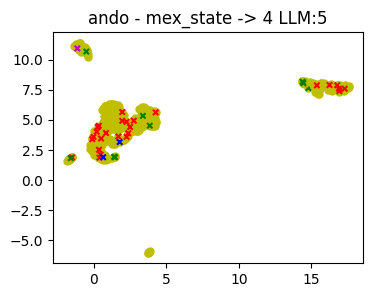

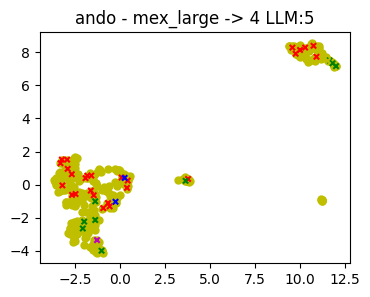

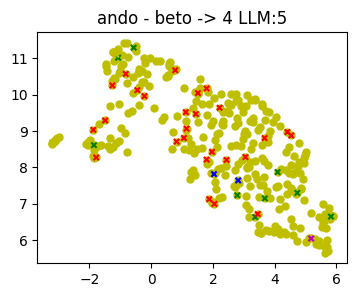

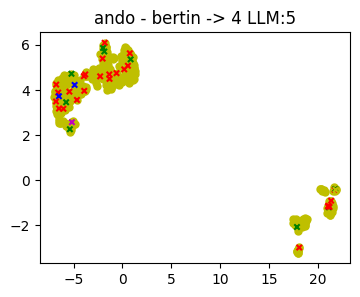

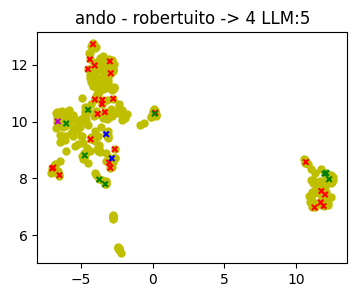

In [194]:
palabra = palabras[0]
modelos = ['mex_state', 'mex_large', 'beto', 'bertin', 'robertuito']
for modelo in modelos:
    muestra_embeddings(modelo, palabra)

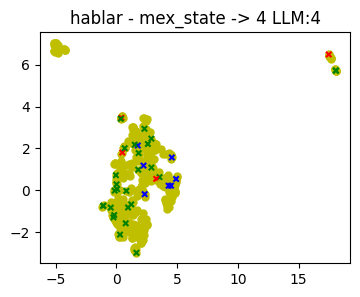

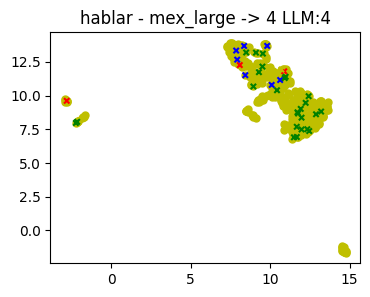

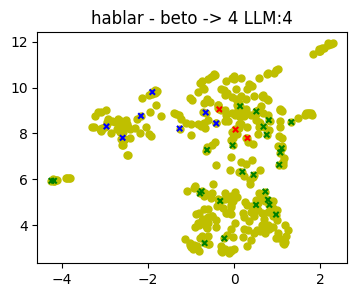

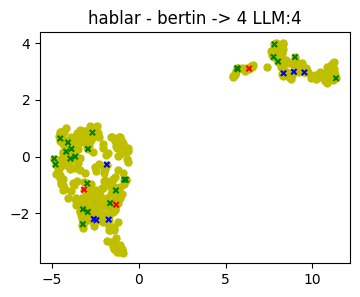

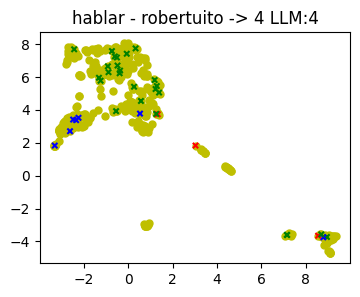

In [195]:
palabra = 'hablar'
modelos = ['mex_state', 'mex_large', 'beto', 'bertin', 'robertuito']
for modelo in modelos:
    muestra_embeddings(modelo, palabra)

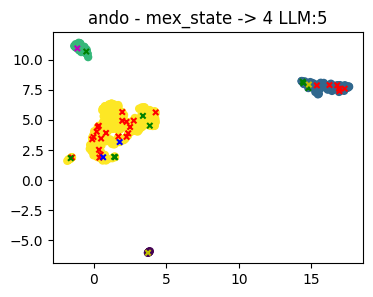

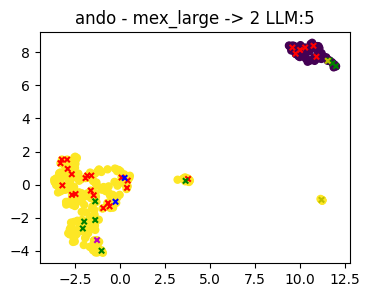

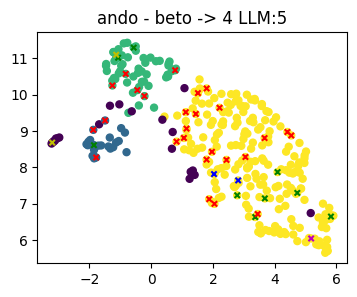

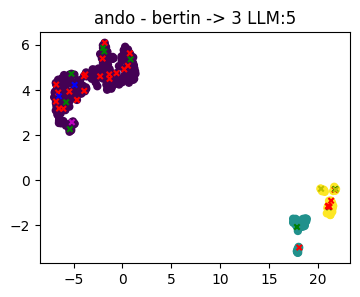

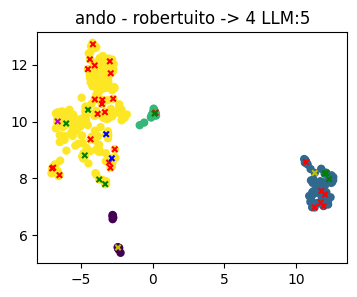

In [180]:
palabra = palabras[0]
modelos = ['mex_state', 'mex_large', 'beto', 'bertin', 'robertuito']
for modelo in modelos:
    muestra_embeddings(modelo, palabra)

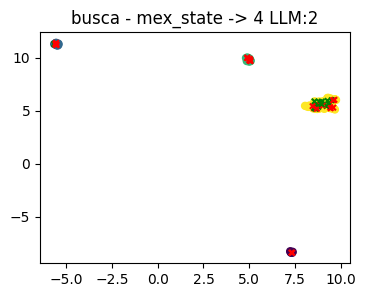

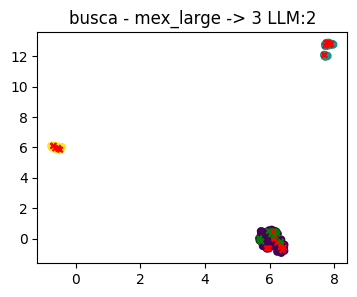

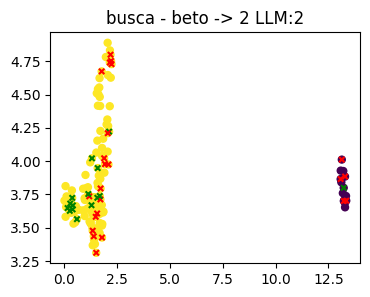

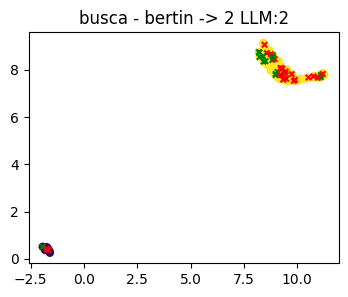

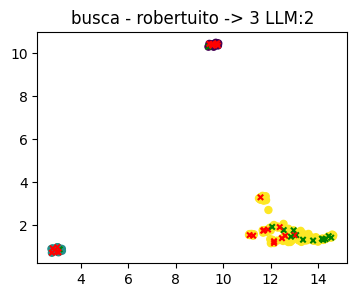

In [190]:
palabra = palabras[2]
modelos = ['mex_state', 'mex_large', 'beto', 'bertin', 'robertuito']
for modelo in modelos:
    muestra_embeddings(modelo, palabra)

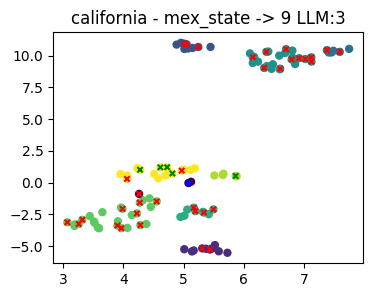

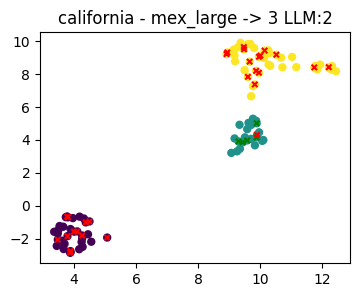

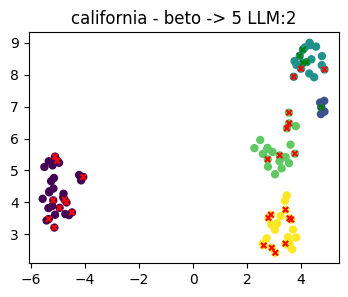

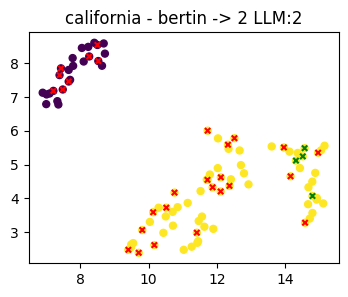

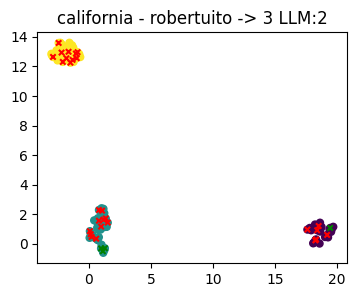

In [113]:
palabra = palabras[3]
modelos = ['mex_state', 'mex_large', 'beto', 'bertin', 'robertuito']
for modelo in modelos:
    muestra_embeddings(modelo, palabra)